# LOOP AIRWISE — Final 47-Feature Model

**Objective:** Predict next-day mean PM2.5 for each city.

This notebook contains the selected 47-feature CatBoost model. It follows a simple, reproducible workflow:

1. Load the official competition data.
2. Explore the data.
3. Create calendar, interaction and historical features.
4. Select the 47 predictors.
5. Validate on the latest 20% of dates.
6. Review model errors.
7. Train on all labelled data and create `submission.csv`.

**Important:** Run the notebook from top to bottom. The validation score is an estimate of performance on future dates; it is not the hidden-test score.


## 1. Problem statement and objective

The task is to predict `target_pm25_tomorrow`: the mean PM2.5 concentration for the next calendar day for each city.

PM2.5 refers to fine particulate matter with an aerodynamic diameter of 2.5 micrometres or smaller. These particles are important in air-quality monitoring because they can penetrate deep into the respiratory system.

**Project objective:** use the official historical pollution, weather, geographical and calendar information to predict the next day's PM2.5 value.

**Important limitation:** the competition dataset contains modelled/reanalysis-style environmental estimates. These should not be described as direct readings from official monitoring stations. Patterns in this dataset also cannot prove that a particular event, including Diwali fireworks, caused a change in pollution.

## 2. Import libraries and locate the raw files

I keep the raw data unchanged. The path helper checks a few common project layouts so the notebook can run either from the project root or from its `notebooks` folder.

In [20]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

TARGET = "target_pm25_tomorrow"
ID_COL = "row_id"
DATE_COL = "date"

TRAIN_PATH = Path("../data/train.csv")
TEST_PATH = Path("../data/test.csv")



## 3. Load data and run quick sanity checks

I first check the number of rows, date coverage, city coverage, duplicate records and missing values. This helps catch data issues before feature engineering.

In [21]:
train_raw = pd.read_csv(TRAIN_PATH, parse_dates=[DATE_COL])
test_raw = pd.read_csv(TEST_PATH, parse_dates=[DATE_COL])

print("Training shape:", train_raw.shape)
print("Test shape:", test_raw.shape)
print("Training date range:", train_raw[DATE_COL].min(), "to", train_raw[DATE_COL].max())
print("Test date range:", test_raw[DATE_COL].min(), "to", test_raw[DATE_COL].max())

display(train_raw.head())

Training shape: (9856, 33)
Test shape: (2464, 32)
Training date range: 2022-08-05 00:00:00 to 2025-12-18 00:00:00
Test date range: 2025-12-19 00:00:00 to 2026-10-22 00:00:00


,row_id,date,city,region,elevation_m,pm2_5_mean,pm2_5_max,pm10_mean,pm10_max,no2_mean,...,wind_speed_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,weather_code,target_month,target_dayofweek,target_dayofyear,target_is_weekend,target_pm25_tomorrow
0,1,2022-08-05,Agra,North,170.0,38.95,80.3,56.82,117.3,28.23,...,11.4,98,13.58,2.92,63,8,5,218,1,53.00
1,2,2022-08-06,Agra,North,170.0,53.00,115.9,77.00,168.1,39.39,...,6.8,81,17.71,3.87,55,8,6,219,1,37.20
2,3,2022-08-07,Agra,North,170.0,37.20,56.2,53.60,81.5,23.31,...,14.8,77,15.13,3.38,63,8,0,220,0,41.79
3,4,2022-08-08,Agra,North,170.0,41.79,48.9,61.23,70.3,21.01,...,15.2,50,19.95,4.36,63,8,1,221,0,33.86
4,5,2022-08-09,Agra,North,170.0,33.86,44.1,54.90,66.4,17.65,...,15.1,71,21.56,5.18,55,8,2,222,0,18.85


In [22]:
print("Cities:", sorted(train_raw["city"].unique()))

print("\\nRows per city:")
display(train_raw["city"].value_counts().sort_index().to_frame("rows"))

print("\\nMissing values in training data:")
display(train_raw.isna().sum().sort_values(ascending=False).head(12).to_frame("missing"))

print("\\nDuplicate rows:", train_raw.duplicated().sum())
print("Duplicate train city-date pairs:", train_raw.duplicated(["city", DATE_COL]).sum())
print("Duplicate test city-date pairs:", test_raw.duplicated(["city", DATE_COL]).sum())

print("\\nTarget column present in training:", TARGET in train_raw.columns)
print("Target column present in test:", TARGET in test_raw.columns)
print("Training row IDs unique:", train_raw[ID_COL].is_unique)
print("Test row IDs unique:", test_raw[ID_COL].is_unique)


Cities: ['Agra', 'Delhi', 'Jaipur', 'Kanpur', 'Kolkata', 'Lucknow', 'Mumbai', 'Varanasi']
\nRows per city:


,rows
city,
Agra,1232
Delhi,1232
Jaipur,1232
Kanpur,1232
Kolkata,1232
Lucknow,1232
Mumbai,1232
Varanasi,1232


\nMissing values in training data:


,missing
row_id,0
date,0
city,0
region,0
elevation_m,0
pm2_5_mean,0
pm2_5_max,0
pm10_mean,0
pm10_max,0
no2_mean,0


\nDuplicate rows: 0
Duplicate train city-date pairs: 0
Duplicate test city-date pairs: 0
\nTarget column present in training: True
Target column present in test: False
Training row IDs unique: True
Test row IDs unique: True


**Initial dataset observations from the supplied files:**
- Training data: **9,856 rows**, covering **1,232 dates**.
- Test data: **2,464 rows**, covering **308 dates**.
- There are **8 cities**, with 1,232 training rows and 308 test rows per city.
- Training dates run from **5 August 2022 to 18 December 2025**.
- Test dates run from **19 December 2025 to 22 October 2026**.
- Each city has a continuous daily sequence in the supplied data, with no duplicate city-date pairs.

Recheck the outputs above if the official files are updated.

## 4. A quick look at the target and pollution variables

I use a small number of plots to understand the target distribution, city-level differences and time patterns. The target is available only in the training file.

Target summary:


,target_pm25_tomorrow
count,9856.00
mean,55.50
std,35.99
min,0.62
25%,28.86
50%,45.07
75%,72.47
max,279.78


Target skewness: 1.354


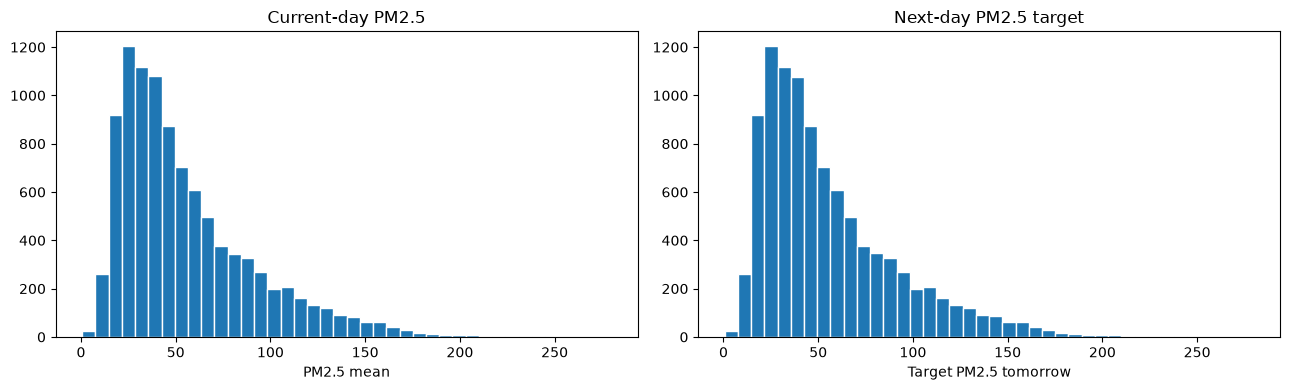

In [23]:
print("Target summary:")
display(train_raw[TARGET].describe().to_frame("target_pm25_tomorrow").round(2))

print("Target skewness:", round(train_raw[TARGET].skew(), 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(train_raw["pm2_5_mean"].dropna(), bins=40, edgecolor="white")
axes[0].set_title("Current-day PM2.5")
axes[0].set_xlabel("PM2.5 mean")

axes[1].hist(train_raw[TARGET].dropna(), bins=40, edgecolor="white")
axes[1].set_title("Next-day PM2.5 target")
axes[1].set_xlabel("Target PM2.5 tomorrow")
plt.tight_layout()
plt.show()

,average_pm25
city,
Delhi,71.40
Agra,67.18
Kolkata,58.22
Lucknow,56.92
Varanasi,56.07
Kanpur,55.39
Mumbai,41.68
Jaipur,36.67


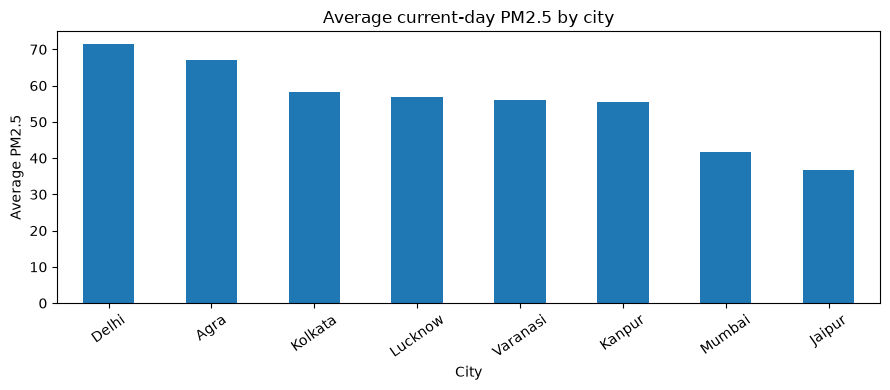

In [24]:
city_pm25 = train_raw.groupby("city")["pm2_5_mean"].mean().sort_values(ascending=False)
display(city_pm25.to_frame("average_pm25").round(2))

city_pm25.plot(kind="bar", figsize=(9, 4), title="Average current-day PM2.5 by city")
plt.ylabel("Average PM2.5")
plt.xlabel("City")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

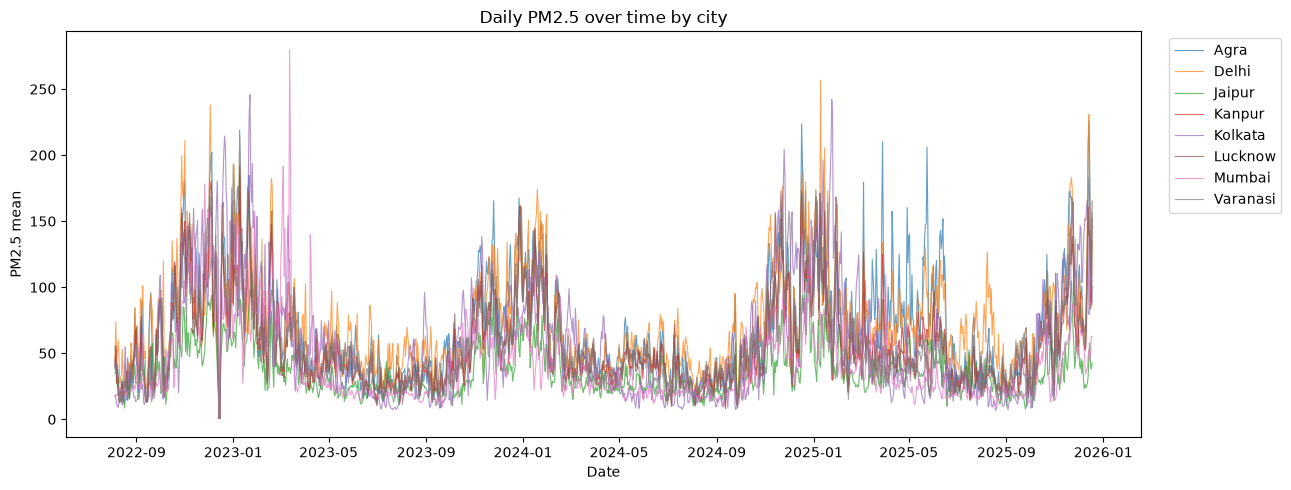

In [25]:
plt.figure(figsize=(13, 5))
for city, city_data in train_raw.groupby("city"):
    city_data = city_data.sort_values(DATE_COL)
    plt.plot(city_data[DATE_COL], city_data["pm2_5_mean"], label=city, linewidth=0.8, alpha=0.7)
plt.title("Daily PM2.5 over time by city")
plt.xlabel("Date")
plt.ylabel("PM2.5 mean")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

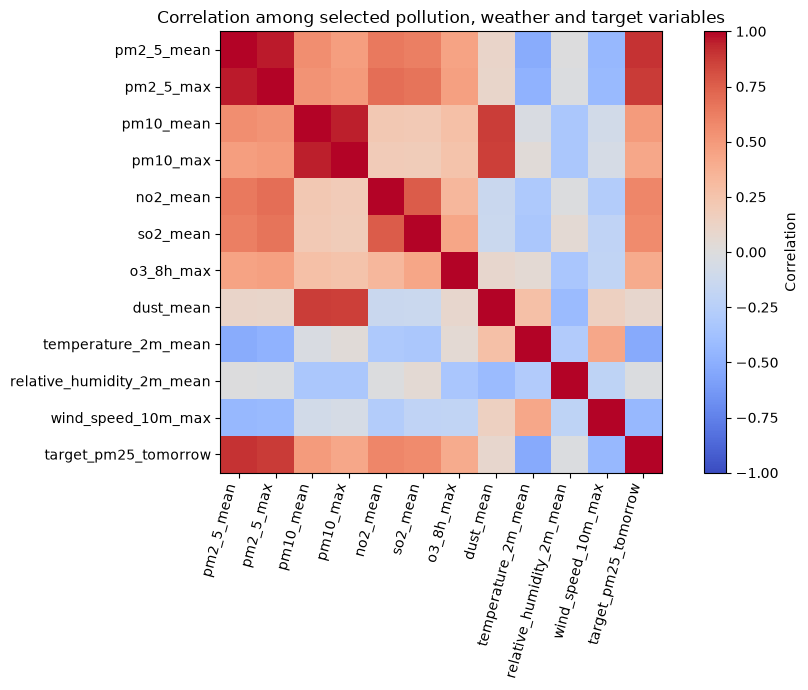

In [26]:
numeric_for_corr = [
    c for c in [
        "pm2_5_mean", "pm2_5_max", "pm10_mean", "pm10_max",
        "no2_mean", "so2_mean", "o3_8h_max", "dust_mean",
        "temperature_2m_mean", "relative_humidity_2m_mean",
        "wind_speed_10m_max", TARGET
    ] if c in train_raw.columns
]

corr = train_raw[numeric_for_corr].corr(numeric_only=True)
plt.figure(figsize=(10, 7))
image = plt.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(image, label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=75, ha="right")
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation among selected pollution, weather and target variables")
plt.tight_layout()
plt.show()

**EDA notes to carry into the report:**
- The target distribution and histogram should be used to describe the spread and whether high-pollution values form a long tail.
- City averages show that pollution levels differ geographically, supporting the use of city information in the full model.
- The time plot helps identify broad seasonal movement and short-term variation. It does not establish why those changes occurred.
- PM2.5 and PM10 are related particulate measurements. Correlation is useful for identifying predictive relationships, but it does not establish causation.

## 5. Feature engineering from the raw data

The competition asks for tomorrow's PM2.5, while each row contains today's observations. I therefore create calendar information for the prediction date and historical features using earlier observed values from the same city.

The target column is deliberately removed before any feature engineering. Rolling features use `shift(1)` so that a row's historical window does not include the current row.

In [27]:
# Keep the target separate. It is never used to build predictor features.
train_features_raw = train_raw.drop(columns=[TARGET]).copy()
train_features_raw["_source"] = "train"
train_features_raw["_original_order"] = np.arange(len(train_features_raw))

test_features_raw = test_raw.copy()
test_features_raw["_source"] = "test"
test_features_raw["_original_order"] = np.arange(len(test_features_raw))

combined = pd.concat([train_features_raw, test_features_raw], ignore_index=True)
combined = combined.sort_values(["city", DATE_COL], kind="mergesort").reset_index(drop=True)

print("Combined rows for chronological feature creation:", len(combined))

Combined rows for chronological feature creation: 12320


In [28]:
# Calendar features from the observation date and the next-day prediction date.
combined["target_date"] = combined[DATE_COL] + pd.Timedelta(days=1)
combined["target_month"] = combined["target_date"].dt.month
combined["target_dayofweek"] = combined["target_date"].dt.dayofweek
combined["target_dayofyear"] = combined["target_date"].dt.dayofyear
combined["year"] = combined[DATE_COL].dt.year
combined["month"] = combined[DATE_COL].dt.month
combined["day"] = combined[DATE_COL].dt.day
combined["dayofweek"] = combined[DATE_COL].dt.dayofweek
combined["dayofyear"] = combined[DATE_COL].dt.dayofyear
combined["is_weekend"] = (combined["dayofweek"] >= 5).astype(int)

# Cyclical calendar encoding.
combined["month_sin"] = np.sin(2 * np.pi * combined["month"] / 12)
combined["month_cos"] = np.cos(2 * np.pi * combined["month"] / 12)
combined["weekday_sin"] = np.sin(2 * np.pi * combined["dayofweek"] / 7)
combined["weekday_cos"] = np.cos(2 * np.pi * combined["dayofweek"] / 7)
combined["dayofyear_sin"] = np.sin(2 * np.pi * combined["dayofyear"] / 365.25)
combined["dayofyear_cos"] = np.cos(2 * np.pi * combined["dayofyear"] / 365.25)

# Wind direction is circular: sine and cosine avoid treating 359° and 1° as far apart.
wind_radians = np.deg2rad(combined["wind_direction_10m_dominant"])
combined["wind_direction_sin"] = np.sin(wind_radians)
combined["wind_direction_cos"] = np.cos(wind_radians)

# Pollution relationships.
combined["pm25_range"] = combined["pm2_5_max"] - combined["pm2_5_mean"]
combined["pm10_range"] = combined["pm10_max"] - combined["pm10_mean"]
combined["pm10_pm25_difference"] = combined["pm10_mean"] - combined["pm2_5_mean"]
combined["pm10_pm25_ratio"] = combined["pm10_mean"] / (combined["pm2_5_mean"] + 1e-6)

# Meteorological interactions.
combined["temperature_range"] = (
    combined["temperature_2m_max"] - combined["temperature_2m_min"]
)
combined["apparent_temperature_difference"] = (
    combined["apparent_temperature_max"] - combined["temperature_2m_max"]
)
combined["wind_humidity_interaction"] = (
    combined["wind_speed_10m_max"] * combined["relative_humidity_2m_mean"]
)
combined["temperature_humidity_interaction"] = (
    combined["temperature_2m_mean"] * combined["relative_humidity_2m_mean"]
)

# Historical lags for selected pollution inputs.
lag_columns = ["pm2_5_mean", "pm2_5_max", "pm10_mean", "pm10_max", "dust_mean"]
for column in lag_columns:
    for lag in [1, 2, 3, 7]:
        combined[f"{column}_lag_{lag}"] = combined.groupby("city", sort=False)[column].shift(lag)

# Rolling summaries use only previous days.
rolling_columns = ["pm2_5_mean", "pm10_mean", "dust_mean"]
for column in rolling_columns:
    previous_values = combined.groupby("city", sort=False)[column].shift(1)
    for window in [3, 7]:
        combined[f"{column}_rolling_mean_{window}"] = (
            previous_values.groupby(combined["city"])
            .transform(lambda values: values.rolling(window, min_periods=window).mean())
        )
        combined[f"{column}_rolling_std_{window}"] = (
            previous_values.groupby(combined["city"])
            .transform(lambda values: values.rolling(window, min_periods=window).std())
        )

# One-day changes in observed pollution measurements.
for column in rolling_columns:
    previous = combined.groupby("city", sort=False)[column].shift(1)
    combined[f"{column}_change_1d"] = combined[column] - previous

# The original 89-column experiment removed region before model fitting.
combined = combined.drop(columns=["region"], errors="ignore")

In [29]:
# Separate the engineered rows and restore their original file order.
train_engineered = (
    combined[combined["_source"] == "train"]
    .sort_values("_original_order")
    .drop(columns=["_source", "_original_order"])
    .reset_index(drop=True)
)

test_engineered = (
    combined[combined["_source"] == "test"]
    .sort_values("_original_order")
    .drop(columns=["_source", "_original_order"])
    .reset_index(drop=True)
)

# Add the target back to the training table only.
train_engineered[TARGET] = train_raw[TARGET].to_numpy()

print("Engineered training data:", train_engineered.shape)
print("Engineered test data:", test_engineered.shape)


Engineered training data: (9856, 90)
Engineered test data: (2464, 89)


## 6. Prepare the full feature set

The original full-feature experiment produced 89 columns in the training table. Three columns are metadata/target (`row_id`, `date`, `target_pm25_tomorrow`), leaving **86 model predictors**. The test table has 88 columns because it has no target.

In [30]:
# Selected 47 predictors from the feature-importance ranking.
# Two ranked columns were not available in this raw-data feature pipeline,
# so the next two available ranked predictors were used.

FEATURES = ['pm2_5_mean', 'pm2_5_max', 'pm2_5_mean_change_1d', 'dayofyear_cos', 'wind_humidity_interaction', 'pm2_5_max_lag_1', 'pm25_range', 'pm10_mean_change_1d', 'temperature_humidity_interaction', 'wind_speed_10m_max', 'pm10_mean_rolling_std_7', 'target_dayofyear', 'o3_8h_max', 'pm10_max', 'pm2_5_mean_rolling_mean_7', 'pm10_max_lag_1', 'pm10_mean', 'pm2_5_mean_rolling_std_7', 'pm2_5_mean_lag_3', 'pm2_5_max_lag_7', 'pm2_5_mean_lag_1', 'temperature_2m_min', 'wind_direction_10m_dominant', 'co_8h_max', 'wind_direction_sin', 'temperature_range', 'precipitation_hours', 'dust_mean', 'pm10_range', 'pm10_pm25_difference', 'dust_mean_rolling_mean_7', 'et0_fao_evapotranspiration', 'precipitation_sum', 'pm2_5_mean_lag_7', 'relative_humidity_2m_mean', 'pm10_max_lag_3', 'pm10_mean_rolling_std_3', 'month_sin', 'pm2_5_mean_rolling_std_3', 'elevation_m', 'no2_mean', 'dayofyear_sin', 'city', 'pm2_5_max_lag_3', 'pm10_max_lag_7', 'apparent_temperature_max', 'pm10_mean_lag_7']

categorical_features = ["city"]
numerical_features = [column for column in FEATURES if column not in categorical_features]

print("Number of selected features:", len(FEATURES))
print("Categorical features:", categorical_features)
print("Numerical features:", len(numerical_features))

display(pd.DataFrame({
    "rank": range(1, len(FEATURES) + 1),
    "feature": FEATURES
}))


Number of selected features: 47
Categorical features: ['city']
Numerical features: 46


,rank,feature
0,1,pm2_5_mean
1,2,pm2_5_max
2,3,pm2_5_mean_change_1d
3,4,dayofyear_cos
4,5,wind_humidity_interaction
5,6,pm2_5_max_lag_1
6,7,pm25_range
7,8,pm10_mean_change_1d
8,9,temperature_humidity_interaction
9,10,wind_speed_10m_max


## 7. Chronological validation split

I hold out the latest 20% of unique dates. All cities for a given date stay together. This follows the competition's recommendation for a future-date prediction problem.

The historical input features for a validation row may use earlier observed input measurements from the same city. No future row and no target value is used to construct those features.

In [31]:
train_engineered = train_engineered.sort_values(DATE_COL).reset_index(drop=True)

unique_dates = np.sort(train_engineered[DATE_COL].unique())
split_index = int(len(unique_dates) * 0.80)
cutoff_date = unique_dates[split_index]

development = train_engineered[train_engineered[DATE_COL] < cutoff_date].copy()
validation = train_engineered[train_engineered[DATE_COL] >= cutoff_date].copy()

X_dev = development[FEATURES].copy()
y_dev = development[TARGET].copy()
X_valid = validation[FEATURES].copy()
y_valid = validation[TARGET].copy()

print("Development rows:", len(development))
print("Validation rows:", len(validation))
print("Development dates:", development[DATE_COL].min(), "to", development[DATE_COL].max())
print("Validation dates:", validation[DATE_COL].min(), "to", validation[DATE_COL].max())
print("Cutoff date:", cutoff_date)

Development rows: 7880
Validation rows: 1976
Development dates: 2022-08-05 00:00:00 to 2025-04-15 00:00:00
Validation dates: 2025-04-16 00:00:00 to 2025-12-18 00:00:00
Cutoff date: 2025-04-16T00:00:00.000000


## 8. Train and evaluate the selected model

MAE is the primary competition metric. RMSE gives extra weight to large errors, while R² describes how much variation in the validation target is explained by the model.

In [32]:
from catboost import CatBoostRegressor

# CatBoost can handle numerical missing values. Categorical columns are converted to strings.
X_dev = X_dev.replace([np.inf, -np.inf], np.nan)
X_valid = X_valid.replace([np.inf, -np.inf], np.nan)

for column in categorical_features:
    X_dev[column] = X_dev[column].fillna("Missing").astype(str)
    X_valid[column] = X_valid[column].fillna("Missing").astype(str)

full_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=3,
    loss_function="RMSE",
    random_seed=RANDOM_STATE,
    verbose=False,
    allow_writing_files=False
)

full_model.fit(X_dev, y_dev, cat_features=categorical_features)
validation_predictions = full_model.predict(X_valid)

validation_mae = mean_absolute_error(y_valid, validation_predictions)
validation_rmse = mean_squared_error(y_valid, validation_predictions) ** 0.5
validation_r2 = r2_score(y_valid, validation_predictions)

print(f"Validation MAE : {validation_mae:.4f}")
print(f"Validation RMSE: {validation_rmse:.4f}")
print(f"Validation R²  : {validation_r2:.4f}")

Validation MAE : 8.6332
Validation RMSE: 12.4391
Validation R²  : 0.8630


In [33]:
validation_results = pd.DataFrame([{
    'model': 'CatBoost Regressor',
    'feature_count': len(FEATURES),
    'MAE': validation_mae,
    'RMSE': validation_rmse,
    'R2': validation_r2
}])
display(validation_results.round(4))


,model,feature_count,MAE,RMSE,R2
0,CatBoost Regressor,47,8.6332,12.4391,0.863


## 9. Understand where the model makes errors

I compare errors by city and by the actual PM2.5 range. This helps identify whether the model is consistently weaker in a particular city or on high-pollution days.

MAE by city:


,MAE
city,
Agra,13.292
Delhi,12.033
Kolkata,8.763
Varanasi,8.089
Kanpur,8.046
Lucknow,7.892
Jaipur,6.778
Mumbai,4.173


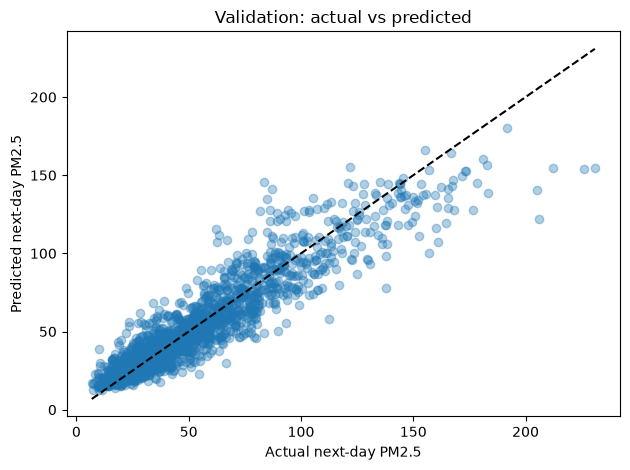

In [34]:
error_analysis = validation[[ID_COL, DATE_COL, "city", TARGET]].copy()
error_analysis["prediction"] = validation_predictions
error_analysis["error"] = error_analysis["prediction"] - error_analysis[TARGET]
error_analysis["absolute_error"] = error_analysis["error"].abs()

print("MAE by city:")
display(
    error_analysis.groupby("city")["absolute_error"]
    .mean().sort_values(ascending=False).to_frame("MAE").round(3)
)

plt.scatter(error_analysis[TARGET], error_analysis["prediction"], alpha=0.35)
lower = min(error_analysis[TARGET].min(), error_analysis["prediction"].min())
upper = max(error_analysis[TARGET].max(), error_analysis["prediction"].max())
plt.plot([lower, upper], [lower, upper], "--", color="black")
plt.xlabel("Actual next-day PM2.5")
plt.ylabel("Predicted next-day PM2.5")
plt.title("Validation: actual vs predicted")
plt.tight_layout()
plt.show()

## 10. Train on all labelled rows and create a candidate submission

After validation, I refit the same model configuration on all labelled training rows. The hidden test labels are not available and are not used. The output file is a candidate submission for this model variant.

In [35]:
X_all = train_engineered[FEATURES].replace([np.inf, -np.inf], np.nan).copy()
X_test = test_engineered[FEATURES].replace([np.inf, -np.inf], np.nan).copy()

for column in categorical_features:
    X_all[column] = X_all[column].fillna("Missing").astype(str)
    X_test[column] = X_test[column].fillna("Missing").astype(str)

final_model = CatBoostRegressor(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    l2_leaf_reg=3,
    loss_function="RMSE",
    random_seed=RANDOM_STATE,
    verbose=False,
    allow_writing_files=False
)

final_model.fit(X_all, train_engineered[TARGET], cat_features=categorical_features)
test_predictions = final_model.predict(X_test)

In [36]:
# Prepare the competition submission in the original test-row order.
submission = pd.DataFrame({
    "row_id": test_raw[ID_COL].to_numpy(),
    "predicted_pm25": test_predictions
})

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

output_path = OUTPUT_DIR / "submission.csv"
submission.to_csv(output_path, index=False)

print("Submission saved to:", output_path.resolve())
print("Submission shape:", submission.shape)
print("Submission columns:", submission.columns.tolist())
print("All predictions present:", submission["predicted_pm25"].notna().all())
print("All predictions finite:", np.isfinite(submission["predicted_pm25"]).all())
print("Row IDs in original test order:", submission["row_id"].tolist() == test_raw[ID_COL].tolist())

print("\\nPrediction summary:")
display(submission["predicted_pm25"].describe().to_frame("predicted_pm25").round(2))
display(submission.head())


Submission saved to: /home/prakhar/Loop-Airwise/outputs/submission.csv
Submission shape: (2464, 2)
Submission columns: ['row_id', 'predicted_pm25']
All predictions present: True
All predictions finite: True
Row IDs in original test order: True
\nPrediction summary:


,predicted_pm25
count,2464.00
mean,57.59
std,33.48
min,12.72
25%,32.38
50%,48.35
75%,76.55
max,171.79


,row_id,predicted_pm25
0,1233,123.088300
1,1234,144.374685
2,1235,149.172305
3,1236,168.491041
4,1237,100.124603
